# DoWhy: Basic Causal Effect Estimation

Based on the DoWhy example
[Basic Example for Calculating the Causal Effect](https://www.pywhy.org/dowhy/main/example_notebooks/dowhy_simple_example.html).

DoWhy breaks causal inference into four steps:

1. **Model**: write down the causal assumptions as a graph.
2. **Identify**: find an estimand (for example backdoor, IV or frontdoor) from the graph alone.
3. **Estimate**: compute the identified estimand from data.
4. **Refute**: stress-test the estimate with checks that a correct estimator should pass.

We simulate data where the true effect of a binary treatment is known (`beta = 10`), so we can check the estimate against it.

In [1]:
import warnings

warnings.filterwarnings("ignore")  # quiet pandas FutureWarnings raised inside DoWhy

import numpy as np
import pandas as pd

import dowhy
import dowhy.datasets
from dowhy import CausalModel

np.random.seed(0)

## 1. Simulate data

The data has linear relationships: 5 common causes (1 discrete), 2 instruments and 1 effect modifier, with a binary treatment `v0` and outcome `y`.
`beta` is the true causal effect.

In [2]:
TRUE_EFFECT = 10

data = dowhy.datasets.linear_dataset(
    beta=TRUE_EFFECT,
    num_common_causes=5,
    num_instruments=2,
    num_effect_modifiers=1,
    num_samples=5000,
    treatment_is_binary=True,
    stddev_treatment_noise=10,
    num_discrete_common_causes=1,
)
df = data["df"]
print("treatment:", data["treatment_name"], "| outcome:", data["outcome_name"])
print("common causes:", data["common_causes_names"])
print("instruments:", data["instrument_names"])
print("effect modifiers:", data["effect_modifier_names"])
df.head()

treatment: ['v0'] | outcome: y
common causes: ['W0', 'W1', 'W2', 'W3', 'W4']
instruments: ['Z0', 'Z1']
effect modifiers: ['X0']


,X0,Z0,Z1,W0,W1,W2,W3,W4,v0,y
0,-0.207904,1.0,0.916913,-0.745097,2.400303,1.471645,-0.416110,3,True,30.279322
1,-1.143040,0.0,0.969514,1.178439,0.914691,0.784667,-0.091816,3,True,28.592166
2,0.263642,0.0,0.177499,-0.276845,0.705577,-0.755228,0.466693,2,False,10.939598
3,-2.021631,1.0,0.261756,0.778194,-1.133118,-0.361171,-0.152383,3,True,17.081029
4,-0.608972,1.0,0.141679,-0.235430,0.477744,1.668267,1.624795,2,True,30.450670


DoWhy expects a pandas DataFrame as input. As a baseline, here is the naive difference in means. It is biased because the common causes affect both treatment and outcome.

In [3]:
t, y = data["treatment_name"][0], data["outcome_name"]
naive = df.loc[df[t], y].mean() - df.loc[~df[t], y].mean()
print(f"Naive difference in means: {naive:.2f} (true effect = {TRUE_EFFECT})")

Naive difference in means: 17.28 (true effect = 10)


## 2. Model — Interface 1 (recommended): supply a causal graph

The graph is given in GML format (DOT also works). Tools such as [DAGitty](http://dagitty.net/dags.html) can draw a graph and export it as a string.

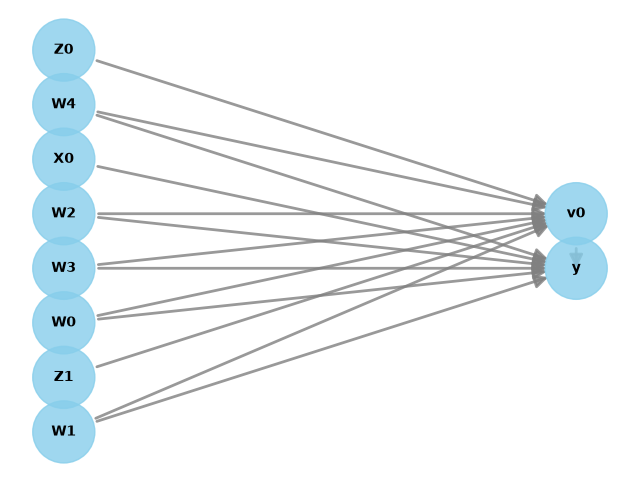

In [4]:
model = CausalModel(
    data=df,
    treatment=data["treatment_name"],
    outcome=data["outcome_name"],
    graph=data["gml_graph"],
)
model.view_model()

## 3. Identify

Identification uses **only the graph**, not the data, so it is a separate step from estimation.
`proceed_when_unidentifiable=True` states that we assume there are no unobserved confounders.

In [5]:
identified_estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d                       
─────(E[y|W1,W0,W3,W2,W4])
d[v₀]                     
Estimand assumption 1, Unconfoundedness: If U→{v0} and U→y then P(y|v0,W1,W0,W3,W2,W4,U) = P(y|v0,W1,W0,W3,W2,W4)

### Estimand : 2
Estimand name: iv
Estimand expression:
 ⎡                              -1⎤
 ⎢    d        ⎛    d          ⎞  ⎥
E⎢─────────(y)⋅⎜─────────([v₀])⎟  ⎥
 ⎣d[Z₁  Z₀]    ⎝d[Z₁  Z₀]      ⎠  ⎦
Estimand assumption 1, As-if-random: If U→→y then ¬(U →→{Z1,Z0})
Estimand assumption 2, Exclusion: If we remove {Z1,Z0}→{v0}, then ¬({Z1,Z0}→y)

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
  d                       
─────(E[y|W1,W0,W3,W2,W4])
d[v₀]                     
Estimand assumption 1, Unconfoundedness: If U→{v0} and U→y then P(y|v0,W1,W0,W3,W2,W4,U) = P(y|v0,W1,W0,W3,W2,W4)



## 4. Estimate

We estimate the backdoor estimand with **propensity score stratification**.

In [6]:
estimate = model.estimate_effect(
    identified_estimand,
    method_name="backdoor.propensity_score_stratification",
)
print(estimate)
print(f"ATE estimate: {estimate.value:.2f} (true effect = {TRUE_EFFECT})")

*** Causal Estimate ***

## Identified estimand
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d                       
─────(E[y|W1,W0,W3,W2,W4])
d[v₀]                     
Estimand assumption 1, Unconfoundedness: If U→{v0} and U→y then P(y|v0,W1,W0,W3,W2,W4,U) = P(y|v0,W1,W0,W3,W2,W4)

## Realized estimand
b: y~v0+W1+W0+W3+W2+W4
Target units: ate

## Estimate
Mean value: 9.502861368741106

ATE estimate: 9.50 (true effect = 10)


`target_units` picks the population the effect is estimated for: `"ate"`, `"att"`, `"atc"`, a row filter (lambda), or a new DataFrame. Below is the effect on the control group (ATC).

In [7]:
estimate_atc = model.estimate_effect(
    identified_estimand,
    method_name="backdoor.propensity_score_stratification",
    target_units="atc",
)
print(f"ATC estimate: {estimate_atc.value:.2f}")

ATC estimate: 9.72


## Interface 2: name the common causes instead of drawing a graph

When no full graph is available, list the common causes (and any effect modifiers or instruments). DoWhy builds the implied graph itself, and identification and estimation work the same way.

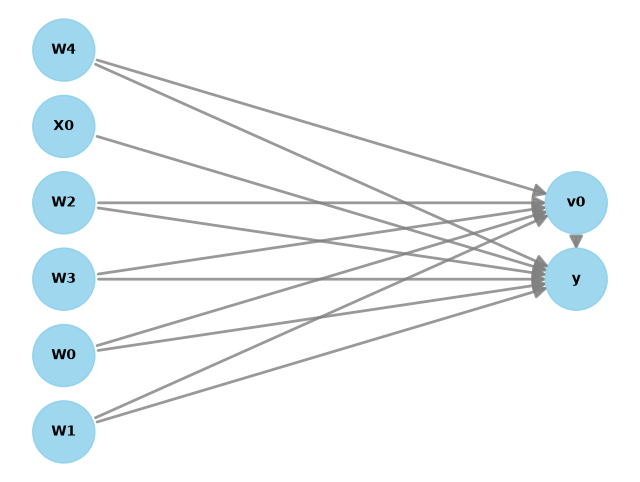

ATE estimate (interface 2): 9.50


In [8]:
model2 = CausalModel(
    data=df,
    treatment=data["treatment_name"],
    outcome=data["outcome_name"],
    common_causes=data["common_causes_names"],
    effect_modifiers=data["effect_modifier_names"],
)
model2.view_model()

identified_estimand2 = model2.identify_effect(proceed_when_unidentifiable=True)
estimate2 = model2.estimate_effect(
    identified_estimand2,
    method_name="backdoor.propensity_score_stratification",
)
print(f"ATE estimate (interface 2): {estimate2.value:.2f}")

## 5. Refute the estimate

Refutations can't prove an estimate is right, but they can show it is wrong.

- **Invariant transformations** should leave the estimate unchanged: *random common cause*, *data subset*.
- **Nullifying transformations** should push the estimate to about zero: *placebo treatment*.

A p-value below 0.05 means the estimator failed the test.

### 5a. Add a random common cause

In [9]:
res_random = model.refute_estimate(
    identified_estimand, estimate,
    method_name="random_common_cause", random_seed=1, n_jobs=-1,
)
print(res_random)

Refute: Add a random common cause
Estimated effect:9.502861368741106
New effect:9.502861368741108
p value:1.0



### 5b. Replace the treatment with a placebo (permuted) variable

In [10]:
res_placebo = model.refute_estimate(
    identified_estimand, estimate,
    method_name="placebo_treatment_refuter", placebo_type="permute",
    random_seed=1, n_jobs=-1,
)
print(res_placebo)

Refute: Use a Placebo Treatment
Estimated effect:9.502861368741106
New effect:-0.00812439178488665
p value:0.94



### 5c. Re-estimate on a random 90% subset

In [11]:
res_subset = model.refute_estimate(
    identified_estimand, estimate,
    method_name="data_subset_refuter", subset_fraction=0.9,
    random_seed=1, n_jobs=-1,
)
print(res_subset)

Refute: Use a subset of data
Estimated effect:9.502861368741106
New effect:9.407065237057394
p value:0.38



`random_seed` makes a refutation reproducible. `n_jobs` runs it in parallel (`-1` uses all CPUs) and is supported by the random common cause, placebo and data subset refuters.

### 5d. Sensitivity to an unobserved common cause

This check returns no p-value. It simulates a confounder of a chosen strength that affects both treatment and outcome, then re-estimates, showing how fast the estimate moves when the "no unobserved confounding" assumption is broken.
Domain knowledge is needed to pick plausible strengths.

In [12]:
res_unobserved = model.refute_estimate(
    identified_estimand, estimate,
    method_name="add_unobserved_common_cause",
    confounders_effect_on_treatment="binary_flip",
    confounders_effect_on_outcome="linear",
    effect_strength_on_treatment=0.01,
    effect_strength_on_outcome=0.02,
)
print(res_unobserved)

Refute: Add an Unobserved Common Cause
Estimated effect:9.502861368741106
New effect:8.462799728660833



Passing an array of strengths returns the *(min, max)* range of the new estimates and plots how the estimate changes as confounding grows.

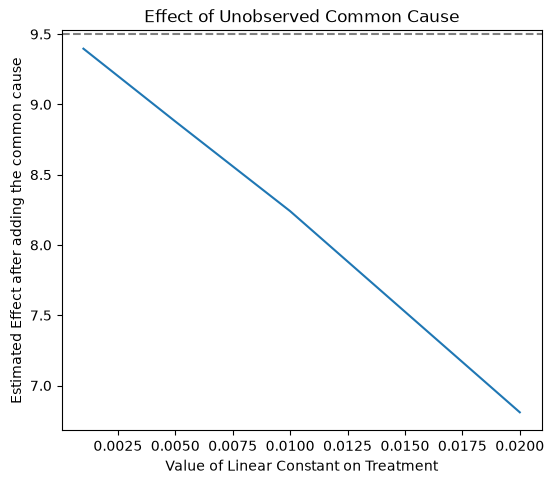

Refute: Add an Unobserved Common Cause
Estimated effect:9.502861368741106
New effect:(np.float64(6.809513861673043), np.float64(9.396437372927966))



In [13]:
res_unobserved_range = model.refute_estimate(
    identified_estimand, estimate,
    method_name="add_unobserved_common_cause",
    confounders_effect_on_treatment="binary_flip",
    confounders_effect_on_outcome="linear",
    effect_strength_on_treatment=np.array([0.001, 0.005, 0.01, 0.02]),
    effect_strength_on_outcome=0.01,
)
print(res_unobserved_range)

Varying the strength on both treatment and outcome produces a heatmap.

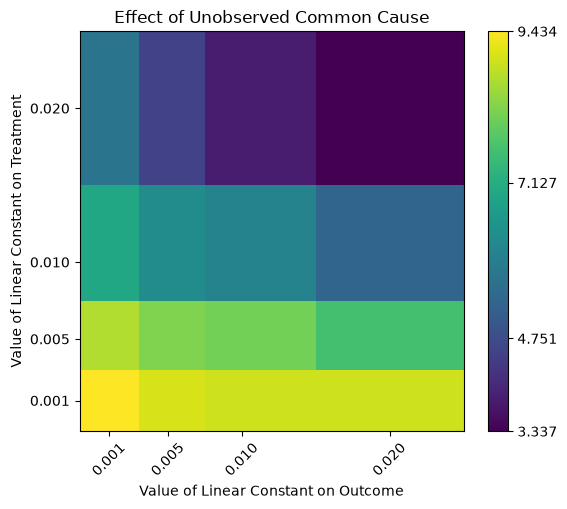

Refute: Add an Unobserved Common Cause
Estimated effect:9.502861368741106
New effect:(np.float64(3.3366461682844), np.float64(9.433862595012995))



In [14]:
res_unobserved_grid = model.refute_estimate(
    identified_estimand, estimate,
    method_name="add_unobserved_common_cause",
    confounders_effect_on_treatment="binary_flip",
    confounders_effect_on_outcome="linear",
    effect_strength_on_treatment=[0.001, 0.005, 0.01, 0.02],
    effect_strength_on_outcome=[0.001, 0.005, 0.01, 0.02],
)
print(res_unobserved_grid)

**Automatic strength bounds.** If no strengths are given, DoWhy bounds them by the strongest *observed* confounder. This assumes no unobserved confounder is stronger than the observed ones.
`effect_fraction_on_treatment` / `effect_fraction_on_outcome` scale that bound (default 1).

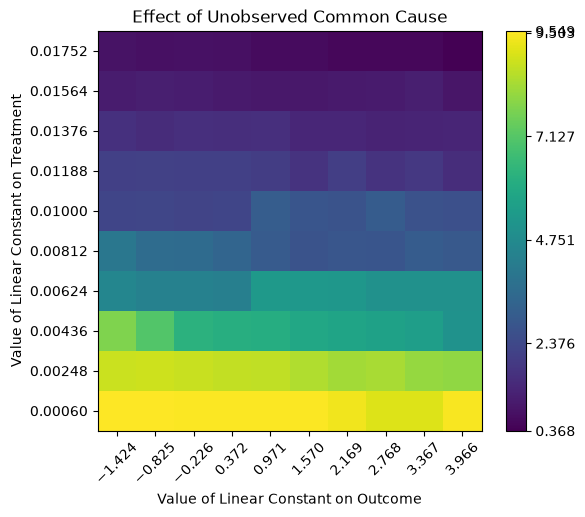

Refute: Add an Unobserved Common Cause
Estimated effect:9.502861368741106
New effect:(np.float64(0.36778054451677666), np.float64(9.549080595074885))



In [15]:
res_unobserved_auto = model.refute_estimate(
    identified_estimand, estimate,
    method_name="add_unobserved_common_cause",
    confounders_effect_on_treatment="binary_flip",
    confounders_effect_on_outcome="linear",
)
print(res_unobserved_auto)

## Summary

In [16]:
pd.DataFrame(
    {
        "value": [
            TRUE_EFFECT, naive, estimate.value, estimate_atc.value, estimate2.value,
            res_random.new_effect, res_placebo.new_effect, res_subset.new_effect,
        ]
    },
    index=[
        "true effect", "naive difference", "ATE (graph)", "ATC (graph)",
        "ATE (common causes)", "refute: random common cause",
        "refute: placebo treatment", "refute: data subset",
    ],
).round(2)

,value
true effect,10.00
naive difference,17.28
ATE (graph),9.50
ATC (graph),9.72
ATE (common causes),9.50
refute: random common cause,9.50
refute: placebo treatment,-0.01
refute: data subset,9.41


**Conclusion.** Propensity score stratification recovers an effect close to the true value of 10, while the naive difference is biased. The estimate passes the invariance checks and drops to about zero under a placebo treatment. Assuming no unobserved confounder is stronger than the observed ones, the effect of `v0` on `y` is positive.